<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/kuis/Nurfinka_Lailasari_PembelajaranMesin_Kelompok2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Persiapan**

### **1.1 Import Library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import time

### **1.2 Membaca Dataset**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abiyyurasyiq/jakarta-house-price-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'jakarta-house-price-dataset' dataset.
Path to dataset files: /kaggle/input/jakarta-house-price-dataset


### **1.3 Menampilkan Data**

In [ ]:
import os

print(os.listdir(path))   # lihat nama file di folder dataset

csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

print(csv_file)
print(df.shape)

['jakarta_house.csv']
jakarta_house.csv
(10000, 9)


In [ ]:
df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


### **1.4 Mengetahui Ukuran Dataset**

In [ ]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

Jumlah baris : 10000
Jumlah kolom : 9


### **1.5 Menampilkan Nama Kolom**

In [ ]:
print('===Nama Kolom===')
for col in df.columns:
    print(col)

===Nama Kolom===
index
price
district
city
bed_rooms
bath_rooms
carport
land_area
building_area


### **1.6 Mengecek Tipe Data**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  object 
 3   city           10000 non-null  object 
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), object(2)
memory usage: 703.3+ KB


### **1.7 Mengecek Missing Value**

In [ ]:
df.isnull().sum()

,0
index,0
price,0
district,0
city,0
bed_rooms,0
bath_rooms,0
carport,0
land_area,3
building_area,5


### **Mengecek Data Duplikat**

In [ ]:
df.duplicated().sum()

print("Jumlah data duplikat :", df.duplicated().sum())

Jumlah data duplikat : 0


# **2. EXPLORATORY DATA ANALYSIS (Nuril_244107020004)**

### **2.1 Statistik Deskriptifk**

In [ ]:
df.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,9997.000000,9995.000000
mean,5000.50000,1.004029e+10,4.253500,3.521300,1.578900,296.610183,319.962481
std,2886.89568,2.004519e+10,3.176609,2.900136,1.743467,502.921686,357.676034
min,1.00000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2500.75000,2.500000e+09,3.000000,2.000000,1.000000,100.000000,139.000000
50%,5000.50000,4.500000e+09,4.000000,3.000000,1.000000,177.000000,230.000000
75%,7500.25000,9.800000e+09,5.000000,4.000000,2.000000,335.000000,400.000000
max,10000.00000,9.000000e+11,63.000000,63.000000,31.000000,17714.000000,15331.000000


### **2.2 Analisis Distribusi Data**

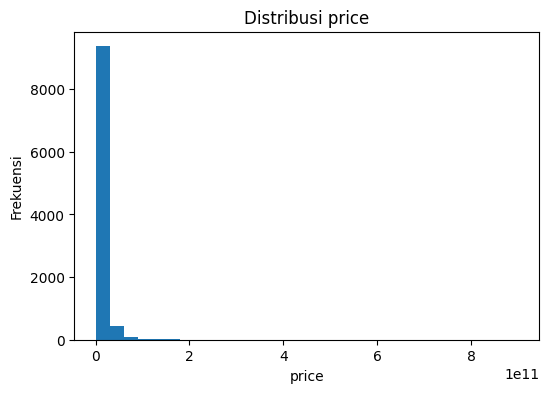

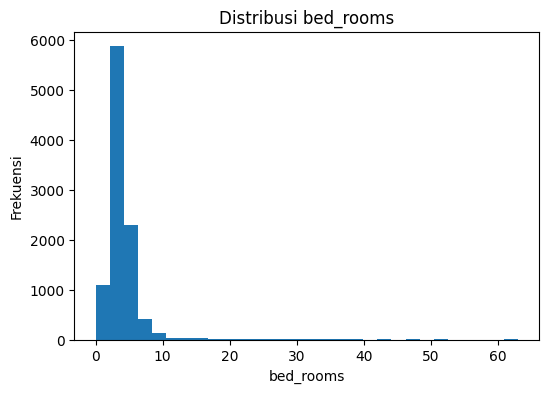

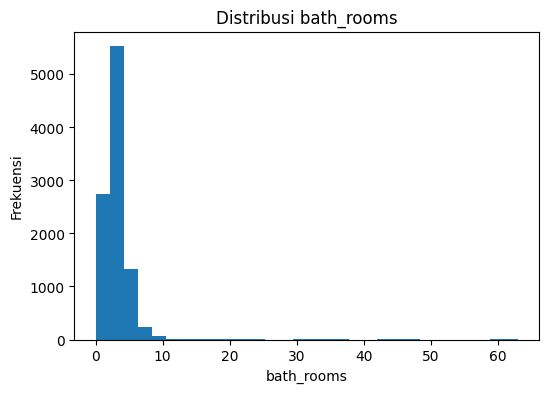

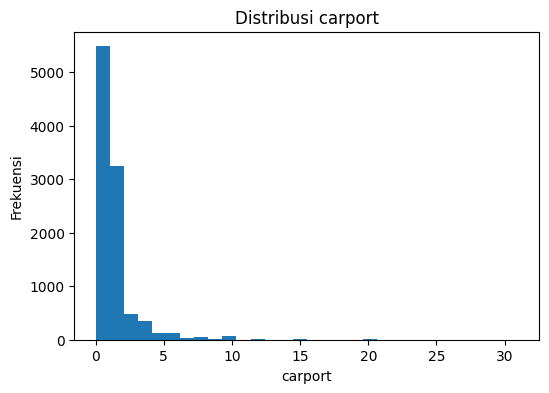

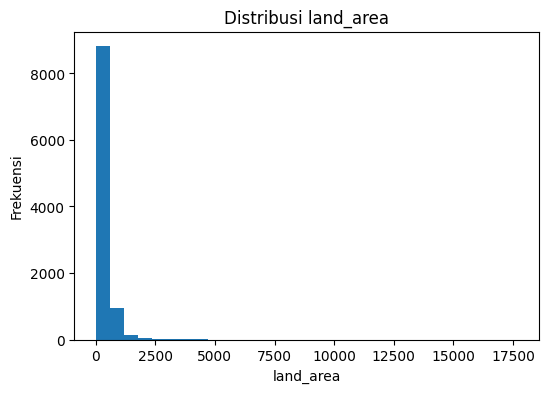

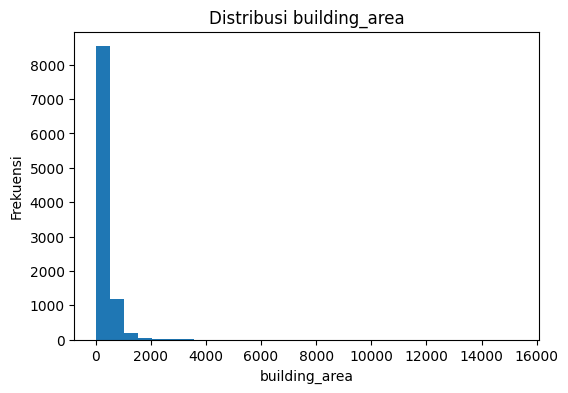

In [ ]:
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.show()

### **2.3 Korelasi Antar Fitur**

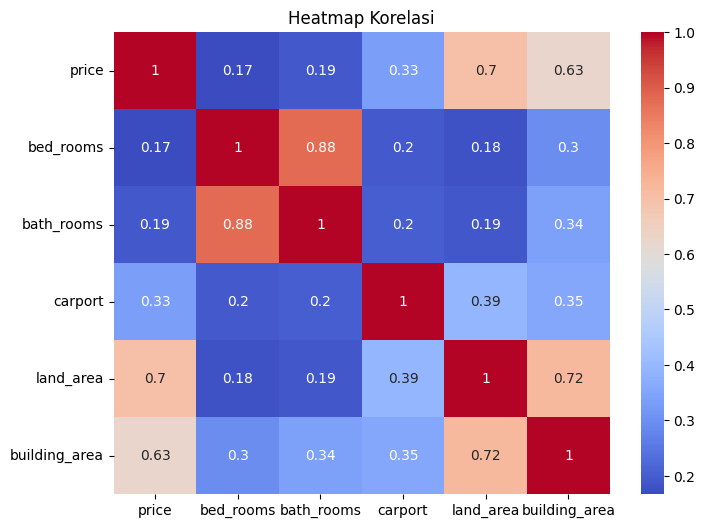

In [ ]:
corr = df[num_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Heatmap Korelasi')
plt.show()

# **3. PRA PENGOLAHAN DATA (Nuril_244107020004)**

### **3.1 Data Imputation / Mengisi Missing Value**

In [ ]:
# Land Area - Mean
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())

# Building Area - Mean
df['building_area'] = df['building_area'].fillna(df['building_area'].mean())



### **3.2 Validasi Hasil Imputasi**

In [ ]:
df.info()

print()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  object 
 3   city           10000 non-null  object 
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      10000 non-null  float64
 8   building_area  10000 non-null  float64
dtypes: float64(2), int64(5), object(2)
memory usage: 703.3+ KB



,0
index,0
price,0
district,0
city,0
bed_rooms,0
bath_rooms,0
carport,0
land_area,0
building_area,0


### **3.3 Deteksi Outlier**

In [ ]:
# Menyimpan batas IQR awal
batas_iqr = {}

# Menentukan Kolom Numerik
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

# Menghitung Nilai Q1, Q3, IQR, Batas Outlier, dan Jumlah Outlier
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    # Simpan batas awal
    batas_iqr[col] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'bawah': batas_bawah,
        'atas': batas_atas
    }

    jumlah_outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ].shape[0]

    print(f"\n===== {col} =====")
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Batas Bawah :", batas_bawah)
    print("Batas Atas :", batas_atas)
    print("Jumlah Outlier :", jumlah_outlier)


===== price =====
Q1 : 2500000000.0
Q3 : 9800000000.0
IQR : 7300000000.0
Batas Bawah : -8450000000.0
Batas Atas : 20750000000.0
Jumlah Outlier : 1107

===== bed_rooms =====
Q1 : 3.0
Q3 : 5.0
IQR : 2.0
Batas Bawah : 0.0
Batas Atas : 8.0
Jumlah Outlier : 308

===== bath_rooms =====
Q1 : 2.0
Q3 : 4.0
IQR : 2.0
Batas Bawah : -1.0
Batas Atas : 7.0
Jumlah Outlier : 270

===== carport =====
Q1 : 1.0
Q3 : 2.0
IQR : 1.0
Batas Bawah : -0.5
Batas Atas : 3.5
Jumlah Outlier : 795

===== land_area =====
Q1 : 100.0
Q3 : 335.0
IQR : 235.0
Batas Bawah : -252.5
Batas Atas : 687.5
Jumlah Outlier : 881

===== building_area =====
Q1 : 139.0
Q3 : 400.0
IQR : 261.0
Batas Bawah : -252.5
Batas Atas : 791.5
Jumlah Outlier : 656


### **3.4 Penanganan Outlier**

In [ ]:
# Menyimpan jumlah data awal
jumlah_awal = len(df)

mask_outlier = pd.Series(False, index=df.index)

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    mask_outlier |= (
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    )

df = df[~mask_outlier]

print("Jumlah data sebelum :", jumlah_awal)
print("Jumlah data sesudah :", len(df))
print("Data yang terhapus :", jumlah_awal - len(df))

Jumlah data sebelum : 10000
Jumlah data sesudah : 8001
Data yang terhapus : 1999


### **3.5 Validasi Hasil Penanganan Outlier**

In [ ]:
# Mengecek Jumlah Data Setelah Penghapusan
for col in num_cols:

    batas_bawah = batas_iqr[col]['bawah']
    batas_atas = batas_iqr[col]['atas']

    jumlah_outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ].shape[0]

    print(f"{col} : {jumlah_outlier}")


price : 0
bed_rooms : 0
bath_rooms : 0
carport : 0
land_area : 0
building_area : 0


### **3.6 Visualisasi Distribusi Data Setelah Penghapusan Outlier**

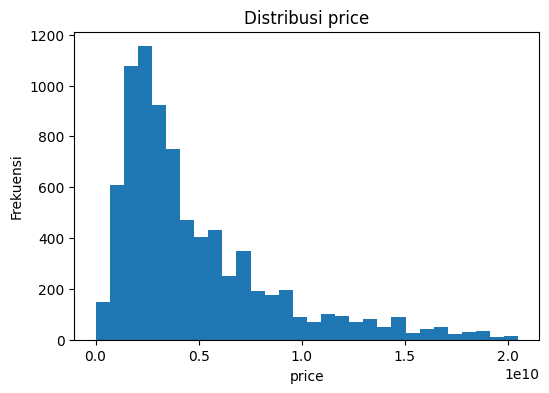

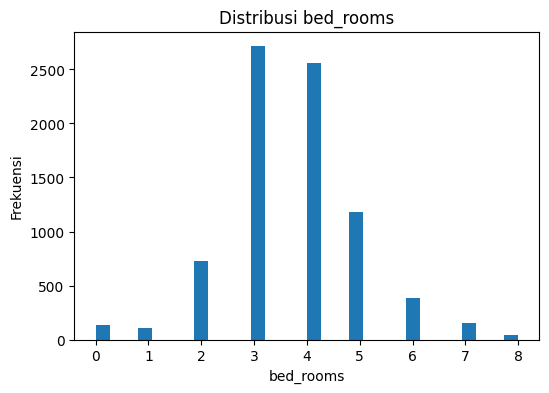

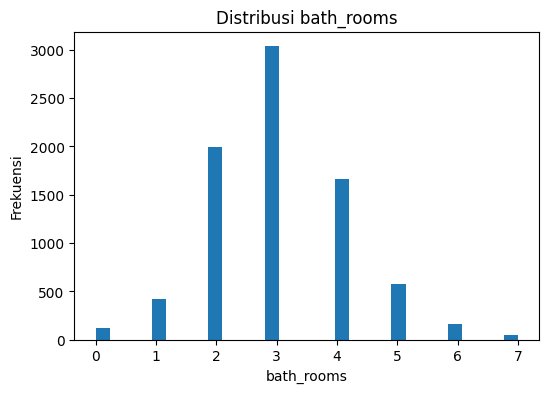

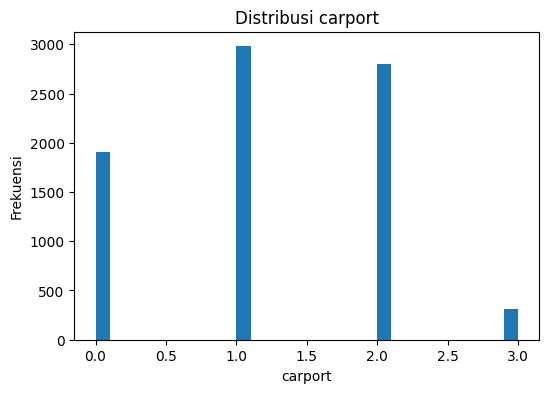

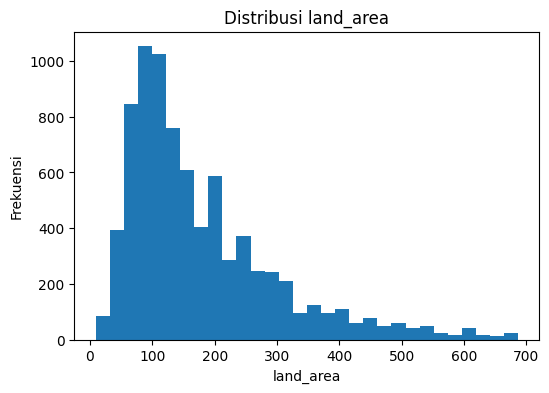

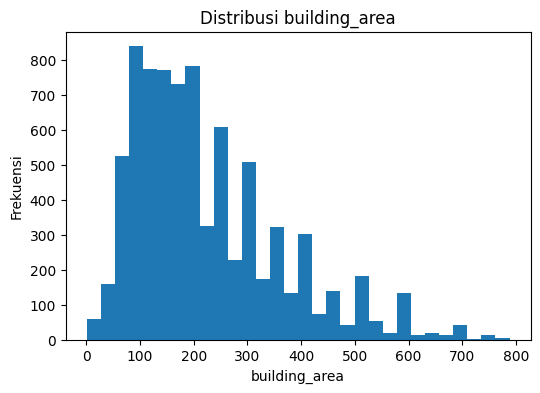

In [ ]:
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.show()

### **3.7 Seleksi Fitur**

In [ ]:
df = df[
    [
        'price',
        'district',
        'city',
        'bed_rooms',
        'bath_rooms',
        'carport',
        'land_area',
        'building_area'
    ]
]

df.head()

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


### **3.8 Encoding data kategorikal**

In [ ]:
le = LabelEncoder()

# District
df['district'] = le.fit_transform(df['district'])

# City
df['city'] = le.fit_transform(df['city'])

### **3.9 Verifikasi Hasil Encoding**

In [ ]:
df[['district', 'city']].head()

,district,city
0,37,0
1,70,0
2,70,0
3,70,0
4,224,0


### **3.10 Standarisasi**

In [ ]:
scaler = StandardScaler()

df = pd.DataFrame(scaler.fit_transform(df),columns=df.columns)


print("================ Hasil Setelah Standardisasi ================")
df.head()

================ Hasil Setelah Standardisasi ================


,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,0.289543,-1.108788,-1.292805,-1.344695,0.832897,0.961320,0.589494,0.909454
1,-0.546548,-0.624150,-1.292805,0.240761,-0.888402,-1.413706,-0.643029,0.006448
2,-0.677188,-0.624150,-1.292805,-0.551967,-0.027752,-1.413706,-0.971701,-0.607597
3,-0.755571,-0.624150,-1.292805,-0.551967,-0.888402,-1.413706,-0.971701,-0.752078
4,-0.703315,1.637498,-1.292805,0.240761,-0.027752,-1.413706,-1.004569,-0.838766


# **4. MENENTUKAN JUMLAH CLUSTER (Nuril_244107020004)**

### **4.1 Metode Elbow**

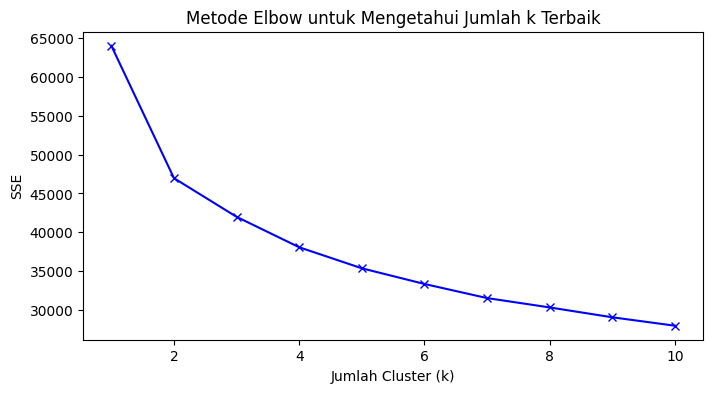

In [ ]:
# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1, 11)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(
     n_clusters=k,
     random_state=42
     )
 kmeanModel.fit(df)
 sse.append(kmeanModel.inertia_)

# Plotting SSE
plt.figure(figsize=(8,4))
plt.plot(K, sse, 'bx-')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('SSE')
plt.title('Metode Elbow untuk Mengetahui Jumlah k Terbaik')
plt.show()

### **Menampilkan Nilai SSE Setiap k**

In [ ]:
for k, nilai_sse in zip(K, sse):
    print(f'k = {k}, SSE = {nilai_sse:.2f}')

k = 1, SSE = 64008.00
k = 2, SSE = 46967.64
k = 3, SSE = 41992.01
k = 4, SSE = 38076.66
k = 5, SSE = 35370.87
k = 6, SSE = 33353.93
k = 7, SSE = 31539.28
k = 8, SSE = 30335.91
k = 9, SSE = 29067.16
k = 10, SSE = 27983.70


### **Evaluasi Jumlah Cluster Menggunakan Silhouette Score**

In [ ]:
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42
        )

    labels = kmeans.fit_predict(df)

    score = silhouette_score(
        df,
        labels
    )

    print(f'k = {k}, silhouette = {score:.4f}')

k = 2, silhouette = 0.2724


KeyboardInterrupt: 

Berdasarkan hasil perhitungan Silhouette Score untuk nilai k = 2 sampai k = 10, diperoleh nilai Silhouette Score tertinggi pada k = 2 yaitu sebesar 0,2724. Nilai ini lebih tinggi dibandingkan nilai k lainnya, sehingga menunjukkan bahwa pembagian data menjadi 2 cluster menghasilkan kualitas cluster yang paling baik. Oleh karena itu, jumlah cluster optimal yang digunakan pada penelitian ini adalah 2 cluster.

# **8. DBSCAN - COSINE (Nurfinka Lailasari_244107020211)**

## **Persiapan**

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import time

X = df.values   # data hasil standarisasi
min_samples_awal = 16   # 2 x jumlah fitur (8 fitur)

## **Visualisasi Data Awal**

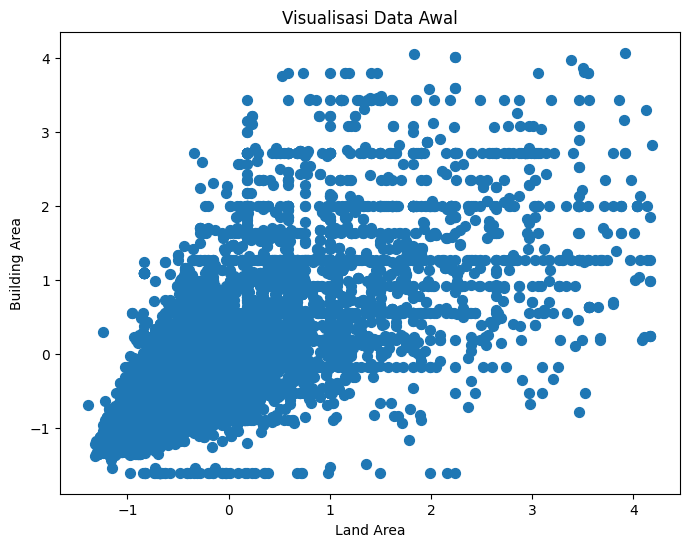

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=50
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('Visualisasi Data Awal')

plt.show()

## **K-distance plot**

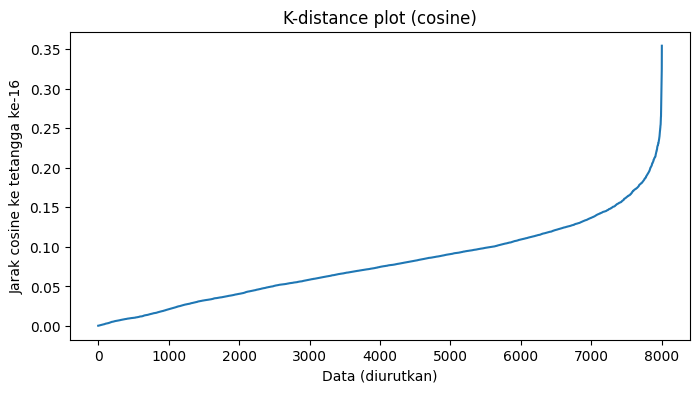

Persentil 50/70/80/90/95: [0.0747 0.1003 0.1189 0.1452 0.1715]


In [ ]:
nn = NearestNeighbors(n_neighbors=min_samples_awal, metric='cosine').fit(X)
dist, _ = nn.kneighbors(X)
k_dist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.xlabel('Data (diurutkan)')
plt.ylabel(f'Jarak cosine ke tetangga ke-{min_samples_awal}')
plt.title('K-distance plot (cosine)')
plt.show()

print('Persentil 50/70/80/90/95:', np.percentile(k_dist, [50, 70, 80, 90, 95]).round(4))

## **Eksperimen eps dan min_samples**

In [ ]:
persentil_list = [50, 70, 80, 90, 95]
ms_list = [8, 16, 32]

baris = []
for p in persentil_list:
    eps = float(np.percentile(k_dist, p))
    for ms in ms_list:
        lab = DBSCAN(eps=eps, min_samples=ms, metric='cosine').fit_predict(X)
        mask = lab != -1
        n_cl = len(set(lab[mask]))
        if n_cl >= 2:
            sil = silhouette_score(X[mask], lab[mask], metric='cosine',
                                   sample_size=min(3000, int(mask.sum())), random_state=42)
        else:
            sil = np.nan
        baris.append({'eps': round(eps, 4), 'min_samples': ms, 'Klaster': n_cl,
                      'Noise': int((~mask).sum()), 'Noise (%)': round(100 * (~mask).mean(), 1),
                      'Silhouette': round(sil, 3)})

grid_cosine = pd.DataFrame(baris)
grid_cosine

,eps,min_samples,Klaster,Noise,Noise (%),Silhouette
0,0.0747,8,13,1110,13.9,-0.544
1,0.0747,16,2,2285,28.6,-0.022
2,0.0747,32,5,3666,45.8,0.263
3,0.1003,8,2,387,4.8,-0.046
4,0.1003,16,2,787,9.8,-0.014
5,0.1003,32,1,1804,22.5,NaN
6,0.1189,8,3,159,2.0,-0.056
7,0.1189,16,1,384,4.8,NaN
8,0.1189,32,1,987,12.3,NaN
9,0.1452,8,1,44,0.5,NaN


## **Pilih parameter dan model final**

In [ ]:
# Pilih otomatis: klaster >= 2, noise <= 30%, Silhouette tertinggi
kandidat = grid_cosine[(grid_cosine['Klaster'] >= 2) & (grid_cosine['Noise (%)'] <= 30)]
if len(kandidat) > 0:
    pilih = kandidat.sort_values('Silhouette', ascending=False).iloc[0]
    eps_final, ms_final = float(pilih['eps']), int(pilih['min_samples'])
else:
    eps_final, ms_final = float(np.percentile(k_dist, 90)), 16

# Atur manual bila perlu, contoh:
# eps_final, ms_final = 0.12, 16

start_time_dbscan = time.time()
db_cos = DBSCAN(eps=eps_final, min_samples=ms_final, metric='cosine')
y_dbscan = db_cos.fit_predict(X)
end_time_dbscan = time.time()

n_clusters_ = len(set(y_dbscan)) - (1 if -1 in y_dbscan else 0)
n_noise_ = list(y_dbscan).count(-1)

print(f'eps = {eps_final}, min_samples = {ms_final}')
print('Jumlah klaster:', n_clusters_)
print('Jumlah noise  :', n_noise_)
print('Anggota per label (-1 = noise):', dict(zip(*np.unique(y_dbscan, return_counts=True))))

eps = 0.1003, min_samples = 16
Jumlah klaster: 2
Jumlah noise  : 787
Anggota per label (-1 = noise): {np.int64(-1): np.int64(787), np.int64(0): np.int64(7201), np.int64(1): np.int64(13)}


## **Model DBSCAN Cosine Distance (Manual)**

In [ ]:
# ==========================
# DBSCAN MANUAL - COSINE
# ==========================
from collections import deque

X_db = df.values
n = len(X_db)

eps_m = eps_final
min_pts_m = ms_final

# Normalisasi tiap baris menjadi vektor satuan, sehingga cos(a, b) = a . b
norm = np.linalg.norm(X_db, axis=1, keepdims=True)
X_unit = X_db / np.clip(norm, 1e-12, None)

# ==========================
# HITUNG JARAK COSINE & CARI TETANGGA
# ==========================
start_manual_cos = time.time()

neighbors_cos = []
for i in range(n):
    # jarak cosine titik i ke semua titik: 1 - cos(theta)
    jarak_i = 1 - X_unit @ X_unit[i]
    neighbors_cos.append(np.where(jarak_i <= eps_m)[0])   # termasuk titik itu sendiri

# ==========================
# TENTUKAN CORE POINT
# ==========================
is_core_cos = np.array([len(t) >= min_pts_m for t in neighbors_cos])

# ==========================
# BENTUK CLUSTER
# ==========================
labels_cos = np.full(n, -1)   # -1 = noise / belum terklaster
cluster_id_cos = 0

for i in range(n):

    # lewati jika bukan core point atau sudah punya cluster
    if not is_core_cos[i] or labels_cos[i] != -1:
        continue

    # mulai cluster baru dari core point i
    labels_cos[i] = cluster_id_cos
    queue = deque([i])

    while queue:
        p = queue.popleft()

        # hanya core point yang boleh memperluas cluster
        if not is_core_cos[p]:
            continue

        for q in neighbors_cos[p]:
            if labels_cos[q] == -1:
                labels_cos[q] = cluster_id_cos
                queue.append(q)

    cluster_id_cos += 1

end_manual_cos = time.time()

# Hasil akhir
y_dbscan_manual = labels_cos

n_cluster_manual = cluster_id_cos
n_noise_manual = int(np.sum(y_dbscan_manual == -1))

print("eps            :", eps_m)
print("min_samples    :", min_pts_m)
print("Jumlah cluster :", n_cluster_manual)
print("Jumlah noise   :", n_noise_manual, f"({n_noise_manual/n*100:.2f}%)")
print("Core points    :", int(is_core_cos.sum()))
print("Anggota per label (-1 = noise):")
print(pd.Series(y_dbscan_manual).value_counts().sort_index())

eps            : 0.1003
min_samples    : 16
Jumlah cluster : 2
Jumlah noise   : 787 (9.84%)
Core points    : 5598
Anggota per label (-1 = noise):
-1     787
 0    7201
 1      13
Name: count, dtype: int64


**Visualisasi**

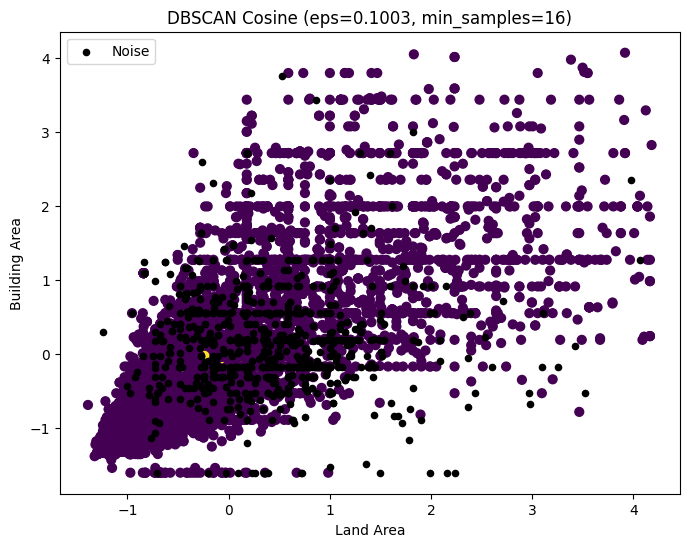

In [ ]:
noise = y_dbscan == -1

plt.figure(figsize=(8, 6))
plt.scatter(df['land_area'][~noise], df['building_area'][~noise],
            c=y_dbscan[~noise], s=40, cmap='viridis')
plt.scatter(df['land_area'][noise], df['building_area'][noise],
            c='black', s=20, label='Noise')
plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title(f'DBSCAN Cosine (eps={eps_final}, min_samples={ms_final})')
plt.legend()
plt.show()

## **Visualisasi Hasil Clustering (Manual)**

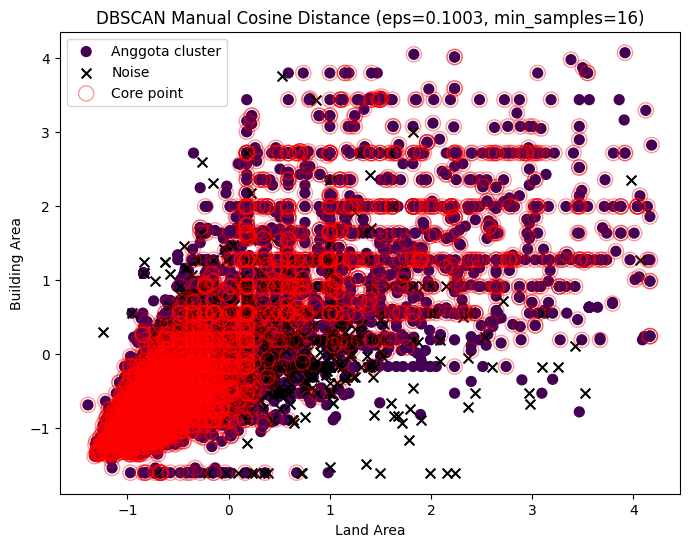

In [ ]:
plt.figure(figsize=(8,6))

noise_m = y_dbscan_manual == -1

# Titik anggota cluster
plt.scatter(
    df['land_area'][~noise_m],
    df['building_area'][~noise_m],
    c=y_dbscan_manual[~noise_m],
    s=50,
    cmap='viridis',
    label='Anggota cluster'
)

# Noise
plt.scatter(
    df['land_area'][noise_m],
    df['building_area'][noise_m],
    c='black',
    marker='x',
    s=50,
    label='Noise'
)

# Core point
plt.scatter(
    df['land_area'][is_core_cos],
    df['building_area'][is_core_cos],
    facecolors='none',
    edgecolors='red',
    s=120,
    alpha=0.4,
    label='Core point'
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title(f'DBSCAN Manual Cosine Distance (eps={eps_m}, min_samples={min_pts_m})')
plt.legend()
plt.show()

**Evaluasi**

In [ ]:
mask = y_dbscan != -1

if len(set(y_dbscan[mask])) >= 2:
    sil_cos = silhouette_score(X[mask], y_dbscan[mask], metric='cosine')
    sil_euc = silhouette_score(X[mask], y_dbscan[mask])
    dbi = davies_bouldin_score(X[mask], y_dbscan[mask])
    chi = calinski_harabasz_score(X[mask], y_dbscan[mask])
else:
    sil_cos = sil_euc = dbi = chi = np.nan

hasil_dbscan_cosine = pd.DataFrame({
    'Metode': ['DBSCAN Cosine'],
    'eps': [eps_final],
    'min_samples': [ms_final],
    'Klaster': [n_clusters_],
    'Noise': [n_noise_],
    'Silhouette (cosine)': [sil_cos],
    'Silhouette (euclidean)': [sil_euc],
    'DBI': [dbi],
    'CHI': [chi],
    'Execution Time': [end_time_dbscan - start_time_dbscan],
})

print("=" * 80)
print("TABEL EVALUASI DBSCAN COSINE (tanpa titik noise)")
print("=" * 80)
print(hasil_dbscan_cosine.to_string(index=False))

TABEL EVALUASI DBSCAN COSINE (tanpa titik noise)
       Metode    eps  min_samples  Klaster  Noise  Silhouette (cosine)  Silhouette (euclidean)      DBI      CHI  Execution Time
DBSCAN Cosine 0.1003           16        2    787            -0.015765               -0.215476 2.663597 2.236907        0.800053


## **Evaluasi DBSCAN (Manual)**

In [ ]:
mask_m = y_dbscan_manual != -1

if len(set(y_dbscan_manual[mask_m])) >= 2:
    sil_cos_m = silhouette_score(X[mask_m], y_dbscan_manual[mask_m], metric='cosine')
    sil_euc_m = silhouette_score(X[mask_m], y_dbscan_manual[mask_m])
    dbi_m = davies_bouldin_score(X[mask_m], y_dbscan_manual[mask_m])
    chi_m = calinski_harabasz_score(X[mask_m], y_dbscan_manual[mask_m])
else:
    sil_cos_m = sil_euc_m = dbi_m = chi_m = np.nan
    print("Peringatan: cluster < 2, metrik tidak dapat dihitung.")

hasil_dbscan_cosine_manual = pd.DataFrame({
    'Metode': ['DBSCAN Cosine Manual'],
    'eps': [eps_m],
    'min_samples': [min_pts_m],
    'Klaster': [n_cluster_manual],
    'Noise': [n_noise_manual],
    'Silhouette (cosine)': [sil_cos_m],
    'Silhouette (euclidean)': [sil_euc_m],
    'DBI': [dbi_m],
    'CHI': [chi_m],
    'Execution Time': [end_manual_cos - start_manual_cos],
})

print("=" * 80)
print("TABEL EVALUASI DBSCAN COSINE MANUAL (tanpa titik noise)")
print("=" * 80)
print(hasil_dbscan_cosine_manual.to_string(index=False))

TABEL EVALUASI DBSCAN COSINE MANUAL (tanpa titik noise)
              Metode    eps  min_samples  Klaster  Noise  Silhouette (cosine)  Silhouette (euclidean)      DBI      CHI  Execution Time
DBSCAN Cosine Manual 0.1003           16        2    787            -0.015765               -0.215476 2.663597 2.236907         0.86256


## **Perbandingan Library dan Manual**

In [ ]:
# Apakah label hasil manual sama dengan library?
sama = np.array_equal(y_dbscan, y_dbscan_manual)
print("Hasil sama dengan library :", sama)
print("Jumlah label berbeda      :", int(np.sum(y_dbscan != y_dbscan_manual)))
print()

hasil_dbscan_cosine_lib = hasil_dbscan_cosine.copy()
hasil_dbscan_cosine_lib['Metode'] = 'DBSCAN Cosine Library'

perbandingan = pd.concat(
    [hasil_dbscan_cosine_lib, hasil_dbscan_cosine_manual],
    ignore_index=True
)

print("=" * 80)
print("PERBANDINGAN DBSCAN COSINE: LIBRARY vs MANUAL")
print("=" * 80)
print(perbandingan.to_string(index=False))

Hasil sama dengan library : True
Jumlah label berbeda      : 0

PERBANDINGAN DBSCAN COSINE: LIBRARY vs MANUAL
               Metode    eps  min_samples  Klaster  Noise  Silhouette (cosine)  Silhouette (euclidean)      DBI      CHI  Execution Time
DBSCAN Cosine Library 0.1003           16        2    787            -0.015765               -0.215476 2.663597 2.236907        0.800053
 DBSCAN Cosine Manual 0.1003           16        2    787            -0.015765               -0.215476 2.663597 2.236907        0.862560
